# 04 · Gold y KPI

## 0. Carga, forma de Gold y función de Wilson

In [1]:
"""
Aquí lo primero que hicimos fue regenerar Gold con la misma función que usa main.py, y cargar los tres archivos de salida:
las construcciones integradas, los KPI y las sensibilidades. Comprobamos que Gold tenga al menos 200 filas, que no haya duplicados por
OBJECTID y que la fecha de corte sea la de la capa y no la de hoy. También probamos la función de Wilson con los dos vectores que nos
dieron, 5 de 10 y 0 de 10, porque todas las tasas del notebook dependen de ella. Antes de seguir dejamos dos avisos: el estrato es de 2015
y las imágenes de 2026, unos once años de distancia, así que los resultados por estrato hablan del estrato de 2015 asignado al barrio; y la
población son 5.146 construcciones de 7 comunas dentro de los polígonos de afectación preliminar, no todas las de Cali. La salida debería
mostrar que las pruebas pasan; eso no prueba que los KPI sean correctos, solo que nuestro intervalo está bien implementado.
"""
import sys, json, sqlite3, math, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.common import ROOT, load_config
from src.transform.build_gold import run_gold, wilson, newcombe
from src.load.load_database import load_to_sqlite

cfg = load_config()
run_gold(); load_to_sqlite()
gold = pd.read_csv(ROOT / 'data/gold/gold_final.csv', dtype={'comuna': str, 'barrio': str, 'codigo_barrio': str, 'codigo_poligono': str})
kp = pd.read_csv(ROOT / 'data/gold/kpis_gold.csv')
sens = pd.read_csv(ROOT / 'data/gold/kpis_sensibilidad.csv')
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.max_colwidth', 80, 'display.max_rows', 120)
print('filas Gold:', len(gold), '>= mínimo', cfg['thresholds']['gold_min_rows'], '| objectid único:', gold.objectid.is_unique)
print('fecha_corte de los KPI:', kp.fecha_corte.unique(), '| imágenes pre/post:', cfg['fechas']['fecha_imagen_pre'], cfg['fechas']['fecha_imagen_post'])
print('Wilson(5,10)  =', [round(x, 4) for x in wilson(5, 10)], '(esperado [0.2366, 0.7634])')
print('Wilson(0,10)  =', [round(x, 4) for x in wilson(0, 10)], '(esperado [0.0, 0.2775])')


2026-11-11 16:25:25 INFO etl.build_gold Inicio etapa gold


2026-11-11 16:25:26 INFO etl.build_gold Entrada: silver_integrated con 5146 construcciones


2026-11-11 16:25:26 INFO etl.build_gold Salida: gold_final=5146 filas | kpis_gold=23 filas (6 indicadores) | sensibilidades=107 filas


2026-11-11 16:25:26 WARNING etl.build_gold muestra baja (< 30 severos) en: estrato_1, estrato_2, estrato_6, estratos_1-2, comuna_09, comuna_17, comuna_18, comuna_20


2026-11-11 16:25:26 INFO etl.build_gold Fin etapa gold (1.10 s)


2026-11-11 16:25:26 INFO etl.load_database Inicio etapa load


... (2 outputs left out)

2026-11-11 16:25:26 INFO etl.load_database kpis_gold: 23 filas cargadas


2026-11-11 16:25:26 INFO etl.load_database kpis_sensibilidad: 107 filas cargadas


2026-11-11 16:25:26 INFO etl.load_database Fin etapa load (0.47 s)


filas Gold: 5146 >= mínimo 200 | objectid único: True
fecha_corte de los KPI: <StringArray>
['2026-09-02']
Length: 1, dtype: str | imágenes pre/post: 2026-03-22 2026-08-11
Wilson(5,10)  = [0.2366, 0.7634] (esperado [0.2366, 0.7634])
Wilson(0,10)  = [0.0, 0.2775] (esperado [0.0, 0.2775])


## 1. K1 · Tasa de severos estrictos por estrato

In [2]:
"""
Esta es la tabla central de K1: para cada estrato mostramos cuántas construcciones tienen datos satelitales (n), cuántas son severas (k),
la tasa con su intervalo de Wilson, el porcentaje sin datos y las cotas extremas. Las cotas salen de suponer que todas las construcciones
sin datos fueron no severas (cota inferior) o todas severas (cota superior), son extremos poco realistas pero nos dicen cuánto podría
mover el resultado esa falta de datos. Nos llamó la atención el estrato 2, con cerca de 27 % sin datos, y que E1, E2 y E6 tienen menos de
30 severos. Esta tabla no demuestra diferencias entre estratos, porque los intervalos se solapan casi todos.
"""
k1 = kp[kp.kpi_id == 'K1'][['grupo', 'numerador', 'denominador', 'valor', 'ic95_inf', 'ic95_sup', 'n_sin_datos', 'pct_sin_datos', 'cota_inf', 'cota_sup', 'muestra_baja']]
print(k1.round(4).to_string(index=False))


    grupo  numerador  denominador  valor  ic95_inf  ic95_sup  n_sin_datos  pct_sin_datos  cota_inf  cota_sup  muestra_baja
estrato_1       20.0        302.0 0.0662    0.0433    0.1001         36.0         0.1065    0.0592    0.1657          True
estrato_2        3.0         92.0 0.0326    0.0112    0.0915         34.0         0.2698    0.0238    0.2937          True
estrato_3       74.0       1173.0 0.0631    0.0505    0.0785        109.0         0.0850    0.0577    0.1427         False
estrato_4      145.0       2095.0 0.0692    0.0591    0.0809        172.0         0.0759    0.0640    0.1398         False
estrato_5       53.0       1031.0 0.0514    0.0395    0.0666         83.0         0.0745    0.0476    0.1221         False
estrato_6        0.0         11.0 0.0000    0.0000    0.2588          0.0         0.0000    0.0000    0.0000          True


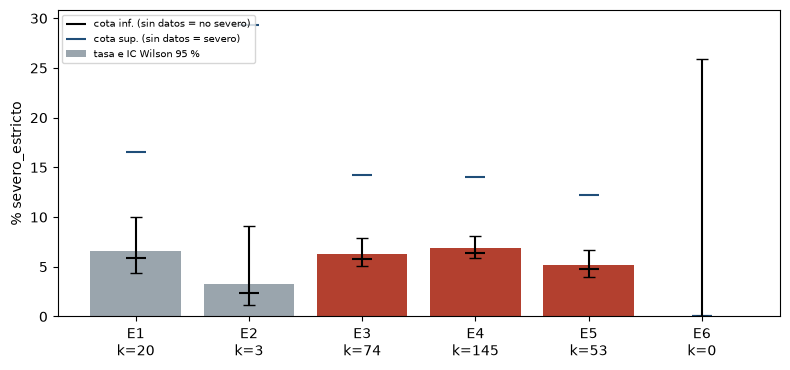

In [3]:
"""
Aquí dibujamos K1 con barras de error de Wilson y, por encima, las cotas extremas por los sin datos como marcas. Lo hicimos porque una
tasa sin su incertidumbre invita a leer diferencias donde no las hay, y porque la falta de datos satelitales no se reparte parejo. Los
estratos con muestra baja los pintamos en gris para que se noten. La figura muestra tasas parecidas entre estratos 1, 3, 4 y 5 y un
intervalo muy ancho en E2 y E6. NO demuestra que el estrato no influya ni que influya: el estrato es de 2015, por lados de manzana, y
está asignado a todo el barrio, así que esto es una descripción de la muestra y no una prueba.
"""
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(k1)); tasa = k1.valor.values * 100
err = np.array([tasa - k1.ic95_inf.values * 100, k1.ic95_sup.values * 100 - tasa])
col = ['#9aa5ad' if b else '#b3402f' for b in k1.muestra_baja]
ax.bar(x, tasa, color=col, yerr=err, capsize=4, label='tasa e IC Wilson 95 %')
ax.scatter(x, k1.cota_inf * 100, marker='_', s=220, color='black', label='cota inf. (sin datos = no severo)')
ax.scatter(x, k1.cota_sup * 100, marker='_', s=220, color='#1f4e79', label='cota sup. (sin datos = severo)')
ax.set_xticks(x); ax.set_xticklabels([g.replace('estrato_', 'E') + f'\nk={int(k)}' for g, k in zip(k1.grupo, k1.numerador)])
ax.set_ylabel('% severo_estricto'); ax.legend(fontsize=7, loc='upper left'); plt.tight_layout(); plt.show()


## 2. K2 · Contraste estratos 3-5 frente a 1-2

In [4]:
"""
Acá comparamos los estratos 3 a 5 contra los estratos 1 y 2, que es el contraste del patrón que se veía a simple vista. Mostramos la razón
de tasas, la diferencia con intervalo de Newcombe y la razón ajustada por comuna de Mantel-Haenszel. Dejamos el estrato 6 fuera porque
solo tiene 11 construcciones. Aplicamos la regla de redacción que nos pusimos: si los intervalos se solapan o la diferencia incluye
cero, solo decimos que con este proxy y esta muestra no se detecta diferencia. La salida muestra además que el ajuste por comuna usa
una sola comuna, y por eso esa razón no se puede interpretar; no es un resultado, es una alerta de confusión.
"""
k2 = kp[kp.kpi_id == 'K2'][['grupo', 'numerador', 'denominador', 'valor', 'ic95_inf', 'ic95_sup', 'cota_inf', 'cota_sup', 'muestra_baja', 'nota']]
print(k2.round(4).to_string(index=False))
dif = kp[kp.grupo == 'diferencia_3-5_menos_1-2'].iloc[0]
print('\nLectura permitida:', dif.nota)
print('¿se solapan los intervalos de Wilson de los dos grupos?',
      not (k2.iloc[0].ic95_inf > k2.iloc[1].ic95_sup or k2.iloc[1].ic95_inf > k2.iloc[0].ic95_sup))
print('¿se solapan las cotas por sin datos? ',
      not (k2.iloc[0].cota_inf > k2.iloc[1].cota_sup or k2.iloc[1].cota_inf > k2.iloc[0].cota_sup), '-> si se solapan, el orden entre grupos no es identificable')


                   grupo  numerador  denominador  valor  ic95_inf  ic95_sup  cota_inf  cota_sup  muestra_baja                                                                                                                                                                                                                                                     nota
            estratos_3-5      272.0       4299.0 0.0633    0.0564    0.0709    0.0583    0.1364         False                                                                                                                                                                                                                                     E6 queda fuera de K2
            estratos_1-2       23.0        394.0 0.0584    0.0392    0.0861    0.0496    0.2004          True                                                                                                                                                                             

## 3. Sensibilidades S0-S5

escenario    tasa  ic95_inf  ic95_sup                                                                                                              nota
       S0  0.0049   -0.0236    0.0255                                                      base; con este proxy y esta muestra no se detecta diferencia
       S1  0.0017   -0.0281    0.0232          nombre_validado = true (principal para la llave); con este proxy y esta muestra no se detecta diferencia
       S2  0.0028   -0.0296    0.0255  coincide_poligono = true (secundaria; no sustituye a S1); con este proxy y esta muestra no se detecta diferencia
       S3 -0.0087   -0.0488    0.0194                                     pureza_estrato >= 0,8; con este proxy y esta muestra no se detecta diferencia
       S4  0.0201   -0.0277    0.0637 dano_visible en lugar de severo_estricto (baja confianza); con este proxy y esta muestra no se detecta diferencia
       S5  0.0042   -0.0245    0.0250                                        sin geom_du

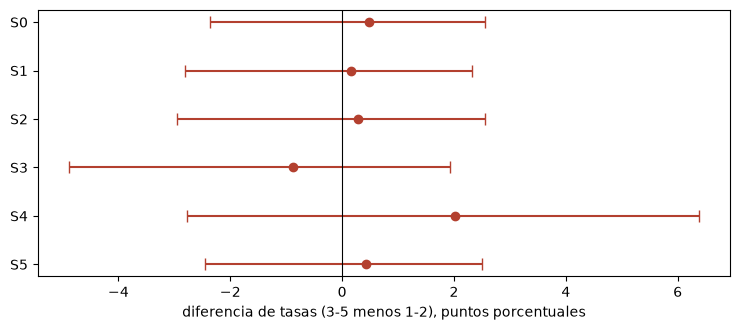

escenario  tasa                                                                                                                                                                                                                                                                                                                  nota
       S0 1.970                                                        base; comunas usadas: 18; excluidas por no tener ambos grupos: 03,09,10,17,19,20; no es interpretable: descansa solo en la Comuna 18 (44 construcciones expuestas con 5 severas y 52 de referencia con 3 severas); el estrato está confundido con la ubicación
       S1 2.315            nombre_validado = true (principal para la llave); comunas usadas: 18; excluidas por no tener ambos grupos: 03,09,10,17,19,20; no es interpretable: descansa solo en la Comuna 18 (36 construcciones expuestas con 5 severas y 50 de referencia con 3 severas); el estrato está confundido con la ubicación
       S2   NaN       

In [5]:
"""
En esta sección repetimos K1, K2 y K6 bajo seis escenarios, para ver si el resultado depende de decisiones nuestras. S0 es la base, S1
usa solo las construcciones con nombre validado, que es la sensibilidad principal de la llave, S2 usa las que coinciden con el polígono,
S3 pide pureza de estrato de al menos 0,8, S4 cambia el indicador por el cambio visible satelital (dano_visible) y S5 quita las geometrías duplicadas. Graficamos la
diferencia de tasas con su intervalo de Newcombe. La figura muestra que en todos los escenarios el intervalo incluye el cero. No
demuestra robustez absoluta: S4 es de baja confianza y S2 no sustituye a S1, porque el 95 % de las que no coinciden por código sí tienen
el nombre validado.
"""
d = sens[sens.grupo == 'diferencia_3-5_menos_1-2'].copy()
print(d[['escenario', 'tasa', 'ic95_inf', 'ic95_sup', 'nota']].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(d))[::-1]
ax.errorbar(d.tasa * 100, y, xerr=[(d.tasa - d.ic95_inf) * 100, (d.ic95_sup - d.tasa) * 100], fmt='o', color='#b3402f', capsize=4)
ax.axvline(0, color='black', lw=.8); ax.set_yticks(y); ax.set_yticklabels(d.escenario)
ax.set_xlabel('diferencia de tasas (3-5 menos 1-2), puntos porcentuales'); plt.tight_layout(); plt.show()
print(sens[sens.grupo == 'razon_MH_ajustada_comuna'][['escenario', 'tasa', 'nota']].round(3).to_string(index=False))


## 4. K6 · Tasa por comuna y confusión estrato × ubicación

    grupo  numerador  denominador  valor  ic95_inf  ic95_sup  pct_sin_datos  muestra_baja
comuna_03       39.0        550.0 0.0709    0.0523    0.0955         0.0998         False
comuna_09        7.0        184.0 0.0380    0.0185    0.0764         0.0891          True
comuna_10       35.0        541.0 0.0647    0.0469    0.0886         0.0624         False
comuna_17        4.0         87.0 0.0460    0.0180    0.1123         0.1212          True
comuna_18        8.0         96.0 0.0833    0.0428    0.1559         0.1504          True
comuna_19      182.0       2909.0 0.0626    0.0543    0.0720         0.0739         False
comuna_20       20.0        342.0 0.0585    0.0382    0.0886         0.1471          True

estrato × comuna (k severos / n con datos); * = menos de 5 severos
comuna       03     09      10     17     18        19      20
estrato                                                       
1.0           -      -       -      -  3/52*         -  17/250
2.0           -      - 

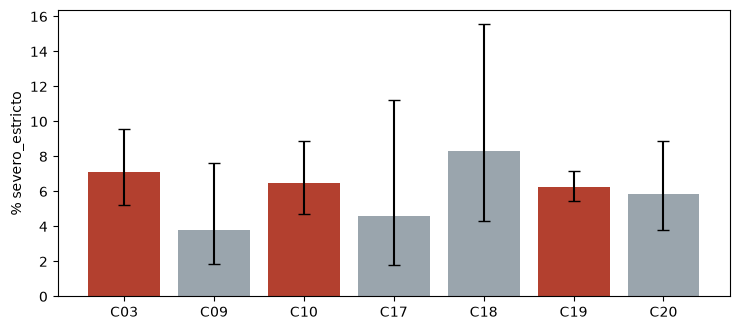

In [6]:
"""
Con K6 respondemos la parte de la pregunta de negocio que dice si el cambio satelital severo se concentra por zona. Mostramos la tasa de severo estricto por
comuna con Wilson, el porcentaje sin datos y la bandera de muestra baja, y al lado la tabla de estrato por comuna con k sobre n,
marcando con asterisco las celdas con menos de 5 severos. Esa tabla nos muestra algo importante, y es que los estratos 1 y 2 están casi
todos en pocas comunas, así que estrato y ubicación van mezclados. La salida no prueba que la zona explique el cambio satelital severo: son solo 7 comunas,
la Comuna 2 no está, y la muestra la definieron los polígonos de afectación.
"""
k6 = kp[kp.kpi_id == 'K6'][['grupo', 'numerador', 'denominador', 'valor', 'ic95_inf', 'ic95_sup', 'pct_sin_datos', 'muestra_baja']]
print(k6.round(4).to_string(index=False))
con = gold[~gold.sin_datos & gold.estrato.notna() & gold.comuna.notna()]
tab = con.groupby(['estrato', 'comuna']).agg(n=('objectid', 'size'), k=('severo_estricto', 'sum')).reset_index()
tab['celda'] = tab.apply(lambda r: f"{int(r.k)}/{int(r.n)}" + ('*' if r.k < 5 else ''), axis=1)
print('\nestrato × comuna (k severos / n con datos); * = menos de 5 severos')
print(tab.pivot(index='estrato', columns='comuna', values='celda').fillna('-').to_string())
fig, ax = plt.subplots(figsize=(7.5, 3.4))
t = k6.valor.values * 100; xs = np.arange(len(k6))
ax.bar(xs, t, color=['#9aa5ad' if b else '#b3402f' for b in k6.muestra_baja],
       yerr=[t - k6.ic95_inf.values * 100, k6.ic95_sup.values * 100 - t], capsize=4)
ax.set_xticks(xs); ax.set_xticklabels([g.replace('comuna_', 'C') for g in k6.grupo]); ax.set_ylabel('% severo_estricto'); plt.tight_layout(); plt.show()


## 5. K3 · Concentración, K4 · Spearman y K5 · calidad del JOIN

kpi_id                                     grupo  valor  numerador  denominador                                                                                                                                                                              nota
    K3                             top10_barrios 0.5661      167.0        295.0 códigos:severos 1914:30; 1913:25; 306:21; 1901:19; 1002:13; 1906:13; 2004:13; 305:12; 1904:11; 1903:10; esos barrios reúnen 48,7 % de las construcciones con datos (2292 de 4709)
    K4 barrios_con_>=10_construcciones_con_datos 0.0348        NaN         45.0                                                                                           n_barrios=45; p_permutacion=0.8218 (5000 permutaciones, seed 0); descriptivo, no causal
    K5                           cobertura_llave 0.9988     5140.0       5146.0                                                                                                                                                   

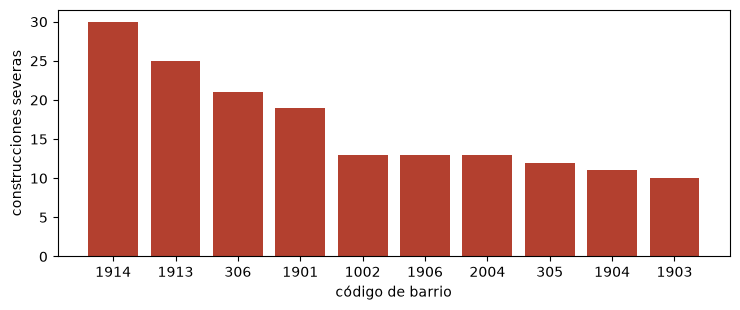

In [7]:
"""
Aquí juntamos los otros tres indicadores. K3 mide qué porcentaje de las construcciones severas está en los 10 barrios con más severos;
K4 es la correlación de Spearman entre el estrato moda del barrio y su tasa de severos, solo para barrios con al menos 10 construcciones
con datos, con un p-valor de permutación; y K5 son las tres coberturas del JOIN. Nos fijamos en que K3 da cerca de 57 %, pero esos
barrios también son los que tienen más construcciones, así que concentración de casos no es lo mismo que mayor riesgo. K4 sale cercano a
cero. Esto es descriptivo: con 45 barrios, una correlación entre dos variables a nivel de barrio no dice nada sobre cada construcción.
"""
print(kp[kp.kpi_id.isin(['K3', 'K4', 'K5'])][['kpi_id', 'grupo', 'valor', 'numerador', 'denominador', 'nota']].round(4).to_string(index=False))
sev = gold[gold.severo_estricto == True]
top = sev.groupby('codigo_barrio').size().rename('severos').reset_index()
top = top.assign(cod=top.codigo_barrio.astype(int)).sort_values(['severos', 'cod'], ascending=[False, True]).head(10)
tot = gold[~gold.sin_datos].groupby('codigo_barrio').size().rename('n_con_datos')
top = top.merge(tot, left_on='codigo_barrio', right_index=True); top['tasa_%'] = (top.severos / top.n_con_datos * 100).round(1)
print(top[['codigo_barrio', 'severos', 'n_con_datos', 'tasa_%']].to_string(index=False))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar(top.codigo_barrio, top.severos, color='#b3402f'); ax.set_xlabel('código de barrio'); ax.set_ylabel('construcciones severas'); plt.tight_layout(); plt.show()


## 6. Recálculo independiente con SQL

In [8]:
"""
Esta es la verificación que más nos importa: recalculamos los KPI desde cero con consultas SQL sobre la base SQLite y los
comparamos con kpis_gold.csv, con tolerancia de 1e-9. Hicimos así porque si el mismo código que calcula los KPI los verifica, un error
se copia a los dos lados; en cambio SQL es otro camino. Verificamos k, n, tasas, cotas, la razón de tasas, la cobertura, K3, K6 y
las sensibilidades S1 a S5. La salida da la diferencia máxima por bloque y si todo cabe en la tolerancia. Lo que NO verifica es que la
definición de los KPI sea la correcta, solo que el cálculo corresponde a esa definición.
"""
conn = None
try:
    conn = sqlite3.connect(ROOT / 'data/gold/etl_sismo.db')
    def q(sql): return pd.read_sql_query(sql, conn)
    TOL = 1e-9
    diffs = {}
    def cmp(nombre, a, b):
        diffs[nombre] = float(np.nanmax(np.abs(np.asarray(a, float) - np.asarray(b, float)))) if len(a) else 0.0
    # K1
    s = q('''SELECT estrato, SUM(severo_estricto) k, COUNT(severo_estricto) n, SUM(sin_datos) sd
             FROM gold_final WHERE estrato IS NOT NULL GROUP BY estrato ORDER BY estrato''')
    s['tasa'] = s.k / s.n; s['ci'] = s.k / (s.n + s.sd); s['cs'] = (s.k + s.sd) / (s.n + s.sd); s['psd'] = s.sd / (s.n + s.sd)
    e = kp[kp.kpi_id == 'K1'].reset_index(drop=True)
    for a, b in (('numerador', 'k'), ('denominador', 'n'), ('valor', 'tasa'), ('cota_inf', 'ci'), ('cota_sup', 'cs'), ('pct_sin_datos', 'psd'), ('n_sin_datos', 'sd')):
        cmp('K1 ' + a, e[a], s[b])
    # K2 (grupos y razón)
    g = q('''SELECT CASE WHEN estrato IN (3,4,5) THEN 'x' ELSE 'r' END g, SUM(severo_estricto) k, COUNT(severo_estricto) n, SUM(sin_datos) sd
             FROM gold_final WHERE estrato IN (1,2,3,4,5) GROUP BY g''').set_index('g')
    rx, rr = g.loc['x', 'k'] / g.loc['x', 'n'], g.loc['r', 'k'] / g.loc['r', 'n']
    k2 = kp[kp.kpi_id == 'K2'].set_index('grupo')
    cmp('K2 tasa 3-5', [k2.loc['estratos_3-5', 'valor']], [rx]); cmp('K2 tasa 1-2', [k2.loc['estratos_1-2', 'valor']], [rr])
    cmp('K2 razón', [k2.loc['razon_3-5_vs_1-2', 'valor']], [rx / rr]); cmp('K2 diferencia', [k2.loc['diferencia_3-5_menos_1-2', 'valor']], [rx - rr])
    # K5
    c5 = q('''SELECT SUM(cruza_llave)*1.0/COUNT(*) a, SUM(estrato IS NOT NULL)*1.0/COUNT(*) b,
                     SUM(CASE WHEN cruza_llave=1 THEN nombre_validado END)*1.0/SUM(cruza_llave) c FROM gold_final''').iloc[0]
    cmp('K5', kp[kp.kpi_id == 'K5'].valor, c5.values)
    # K6
    c6 = q('''SELECT comuna, SUM(severo_estricto) k, COUNT(severo_estricto) n FROM gold_final WHERE comuna IS NOT NULL GROUP BY comuna ORDER BY comuna''')
    cmp('K6 tasa', kp[kp.kpi_id == 'K6'].valor, c6.k / c6.n); cmp('K6 k', kp[kp.kpi_id == 'K6'].numerador, c6.k)
    # K3
    t3 = q('''SELECT codigo_barrio, SUM(severo_estricto) k FROM gold_final WHERE codigo_barrio IS NOT NULL AND severo_estricto=1
              GROUP BY codigo_barrio ORDER BY k DESC, CAST(codigo_barrio AS INTEGER) LIMIT 10''')
    tot3 = q('SELECT COUNT(*) c FROM gold_final WHERE codigo_barrio IS NOT NULL AND severo_estricto=1').c[0]
    cmp('K3', [kp[kp.kpi_id == 'K3'].valor.iloc[0]], [t3.k.sum() / tot3])
    # sensibilidades S1-S5 (K2: k y n de los dos grupos)
    filtros = {'S1': 'nombre_validado=1', 'S2': 'coincide_poligono=1', 'S3': 'pureza_estrato>=0.8', 'S5': 'geom_duplicada=0'}
    for sid, w in filtros.items():
        r = q(f'''SELECT CASE WHEN estrato IN (3,4,5) THEN 'x' ELSE 'r' END g, SUM(severo_estricto) k, COUNT(severo_estricto) n
                  FROM gold_final WHERE estrato IN (1,2,3,4,5) AND {w} GROUP BY g''').set_index('g')
        ss = sens[(sens.escenario == sid)].set_index('grupo')
        cmp(f'{sid} k,n', [ss.loc['estratos_3-5', 'k'], ss.loc['estratos_3-5', 'n'], ss.loc['estratos_1-2', 'k'], ss.loc['estratos_1-2', 'n']],
            [r.loc['x', 'k'], r.loc['x', 'n'], r.loc['r', 'k'], r.loc['r', 'n']])
    r = q('''SELECT CASE WHEN estrato IN (3,4,5) THEN 'x' ELSE 'r' END g, SUM(dano_visible) k, COUNT(dano_visible) n FROM gold_final
             WHERE estrato IN (1,2,3,4,5) GROUP BY g''').set_index('g'); ss = sens[sens.escenario == 'S4'].set_index('grupo')
    cmp('S4 k,n', [ss.loc['estratos_3-5', 'k'], ss.loc['estratos_3-5', 'n']], [r.loc['x', 'k'], r.loc['x', 'n']])
finally:
    if conn is not None:
        conn.close()
res = pd.Series(diffs, name='diferencia máxima')
print(res.to_string()); print('\ntodo dentro de 1e-9:', bool((res <= TOL).all()))


K1 numerador        0.000000e+00
K1 denominador      0.000000e+00
K1 valor            1.933176e-13
K1 cota_inf         4.761920e-13
K1 cota_sup         4.693468e-13
K1 pct_sin_datos    4.775486e-13
K1 n_sin_datos      0.000000e+00
K2 tasa 3-5         2.256251e-13
K2 tasa 1-2         2.335007e-13
K2 razón            2.651213e-13
K2 diferencia       7.871308e-15
K5                  1.504352e-13
K6 tasa             3.333306e-13
K6 k                0.000000e+00
K3                  2.542411e-13
S1 k,n              0.000000e+00
S2 k,n              0.000000e+00
S3 k,n              0.000000e+00
S5 k,n              0.000000e+00
S4 k,n              0.000000e+00

todo dentro de 1e-9: True


In [9]:
"""
Como SQLite no trae raíz cuadrada, Wilson, Newcombe, Mantel-Haenszel y Spearman los verificamos en pandas con una implementación
independiente de la de src/. Para Wilson resolvemos directamente la ecuación cuadrática, para Newcombe usamos esos límites, para
Mantel-Haenszel armamos la fórmula con conteos que salen de la base, y para Spearman calculamos los rangos a mano y la correlación con
numpy, repitiendo las permutaciones con la misma semilla. También volvemos a pasar los dos vectores de prueba. Si todo coincide, sabemos
que el cálculo es consistente con la definición; no sabemos si el intervalo de Wilson es la mejor opción para estos datos.
"""
def wilson_cuad(k, n, z=1.96):
    p = k / n; a = 1 + z * z / n; b = -(2 * p + z * z / n); c = p * p
    r = math.sqrt(b * b - 4 * a * c); return max(0.0, (-b - r) / (2 * a)), min(1.0, (-b + r) / (2 * a))
print('vectores:', [round(v, 4) for v in wilson_cuad(5, 10)], [round(v, 4) for v in wilson_cuad(0, 10)])
conn = None
try:
    conn = sqlite3.connect(ROOT / 'data/gold/etl_sismo.db')
    g = pd.read_sql_query('''SELECT CASE WHEN estrato IN (3,4,5) THEN 'x' ELSE 'r' END g, SUM(severo_estricto) k, COUNT(severo_estricto) n
                             FROM gold_final WHERE estrato IN (1,2,3,4,5) GROUP BY g''', conn).set_index('g')
    mh = pd.read_sql_query('''SELECT comuna, CASE WHEN estrato IN (3,4,5) THEN 'x' ELSE 'r' END g, SUM(severo_estricto) k, COUNT(severo_estricto) n
                              FROM gold_final WHERE estrato IN (1,2,3,4,5) AND comuna IS NOT NULL GROUP BY comuna, g''', conn)
    barr = pd.read_sql_query('''SELECT codigo_barrio, MAX(estrato) estrato, SUM(severo_estricto)*1.0/COUNT(severo_estricto) tasa, COUNT(severo_estricto) n
                                FROM gold_final WHERE codigo_barrio IS NOT NULL AND estrato IS NOT NULL GROUP BY codigo_barrio''', conn)
finally:
    if conn is not None:
        conn.close()
(kx, nx), (kr, nr) = (g.loc['x', ['k', 'n']].values, g.loc['r', ['k', 'n']].values)
p1, p0 = kx / nx, kr / nr; l1, u1 = wilson_cuad(kx, nx); l0, u0 = wilson_cuad(kr, nr)
d = p1 - p0; ni = d - math.sqrt((p1 - l1) ** 2 + (u0 - p0) ** 2); ns = d + math.sqrt((u1 - p1) ** 2 + (p0 - l0) ** 2)
fila = kp[kp.grupo == 'diferencia_3-5_menos_1-2'].iloc[0]
print('Newcombe  independiente:', round(d, 12), round(ni, 12), round(ns, 12), '| kpis_gold:', round(fila.valor, 12), round(fila.ic95_inf, 12), round(fila.ic95_sup, 12))
w = mh.pivot(index='comuna', columns='g', values=['k', 'n']).dropna()
num = sum(w.loc[c, ('k', 'x')] * w.loc[c, ('n', 'r')] / (w.loc[c, ('n', 'x')] + w.loc[c, ('n', 'r')]) for c in w.index)
den = sum(w.loc[c, ('k', 'r')] * w.loc[c, ('n', 'x')] / (w.loc[c, ('n', 'x')] + w.loc[c, ('n', 'r')]) for c in w.index)
print('Mantel-Haenszel independiente:', round(num / den, 12), '| comunas con ambos grupos:', list(w.index), '| kpis_gold:', kp[kp.grupo == 'razon_MH_ajustada_comuna'].valor.iloc[0])
b = barr[(barr.n >= cfg['thresholds']['min_edificios_por_barrio'])].copy()
def rangos(v):
    o = sorted(range(len(v)), key=lambda i: v[i]); r = [0.0] * len(v); i = 0
    while i < len(o):
        j = i
        while j + 1 < len(o) and v[o[j + 1]] == v[o[i]]: j += 1
        for t in range(i, j + 1): r[o[t]] = (i + j) / 2 + 1
        i = j + 1
    return r
rx_, ry_ = rangos(b.estrato.tolist()), rangos(b.tasa.tolist())
rho = np.corrcoef(rx_, ry_)[0, 1]
rng = random.Random(0); ge = 0; yy = list(ry_)
for _ in range(5000):
    rng.shuffle(yy)
    if abs(np.corrcoef(rx_, yy)[0, 1]) >= abs(rho) - 1e-12: ge += 1
print('Spearman independiente: rho =', round(rho, 12), 'n =', len(b), 'p =', round((1 + ge) / 5001, 4), '| kpis_gold:', round(kp[kp.kpi_id == 'K4'].valor.iloc[0], 12), kp[kp.kpi_id == 'K4'].nota.iloc[0][:60])


vectores: [0.2366, 0.7634] [0.0, 0.2775]
Newcombe  independiente: 0.004894893512 -0.023644743364 0.025539919147 | kpis_gold: 0.004894893512 -0.023644743364 0.025539919147
Mantel-Haenszel independiente: 1.969696969697 | comunas con ambos grupos: ['18'] | kpis_gold: 1.969696969697


Spearman independiente: rho = 0.034800697318 n = 45 p = 0.8218 | kpis_gold: 0.034800697318 n_barrios=45; p_permutacion=0.8218 (5000 permutaciones, seed


## 7. Qué no se puede concluir

In [10]:
"""
Para cerrar escribimos de forma explícita lo que estos resultados NO permiten decir, porque creemos que es tan importante como lo que
muestran. El proxy mide cambio visible desde el satélite, no daño interno ni una evaluación estructural; solo hay siete comunas y la
Comuna 2 no está, así que las tasas describen esta muestra y no se extrapolan a las construcciones de Cali ni a la ciudad. El estrato es
de 2015, unos once años antes de las imágenes de 2026, y se asigna por lados de manzana a todo el barrio; el estrato 2 tiene mucha falta de
datos y no es aleatoria; varios estratos tienen muestra baja; el cambio visible (dano_visible) es de baja confianza; y asociación no es
causa. La celda imprime la lista con las cifras actuales de Gold. Con este proxy y esta muestra no se detecta diferencia entre estratos, y
eso no equivale a decir que el estrato no influye.
"""
e2 = kp[(kp.grupo == 'estrato_2')].iloc[0]; hb = gold[gold.cruza_llave & (gold.pureza_estrato < .8)]
lista = [
    f"1) El proxy mide cambio visible desde satélite (imágenes {cfg['fechas']['fecha_imagen_pre']} y {cfg['fechas']['fecha_imagen_post']}), no daño interno ni construcciones de varios pisos sin cambio visible.",
    f"2) Solo {gold.comuna.nunique()} comunas ({', '.join(sorted(gold.comuna.dropna().unique()))}); la Comuna 2 no está: las tasas no se extrapolan a las construcciones de Cali.",
    f"3) El estrato 2 tiene {e2.pct_sin_datos * 100:.1f} % de construcciones sin datos satelitales y la falta de datos no es aleatoria.",
    f"4) Estratos con muestra baja (< {cfg['silver']['muestra_baja_severos']} severos): {', '.join(kp[(kp.kpi_id == 'K1') & kp.muestra_baja].grupo)}; también el grupo estratos 1-2 de K2.",
    f"5) Estrato 2015 por lados de manzana asignado a todo el barrio (falacia ecológica); {len(hb)} construcciones están en barrios con pureza < 0,8.",
    "6) dano_visible (S4) es de baja confianza: 22,5 % de las construcciones con datos son 'techo' y no hay grupo de control entre las imágenes.",
    "7) Asociación no es causa; el ajuste por comuna no es informativo porque los estratos 1-2 están casi todos en una comuna.",
]
print('\n'.join(lista))


1) El proxy mide cambio visible desde satélite (imágenes 2026-03-22 y 2026-08-11), no daño interno ni construcciones de varios pisos sin cambio visible.
2) Solo 7 comunas (03, 09, 10, 17, 18, 19, 20); la Comuna 2 no está: las tasas no se extrapolan a las construcciones de Cali.
3) El estrato 2 tiene 27.0 % de construcciones sin datos satelitales y la falta de datos no es aleatoria.
4) Estratos con muestra baja (< 30 severos): estrato_1, estrato_2, estrato_6; también el grupo estratos 1-2 de K2.
5) Estrato 2015 por lados de manzana asignado a todo el barrio (falacia ecológica); 1480 construcciones están en barrios con pureza < 0,8.
6) dano_visible (S4) es de baja confianza: 22,5 % de las construcciones con datos son 'techo' y no hay grupo de control entre las imágenes.
7) Asociación no es causa; el ajuste por comuna no es informativo porque los estratos 1-2 están casi todos en una comuna.
